# Entrenamiento y validación de los tres modelos

### Selección de modelos, variantes y métricas de evaluación

Se seleccionaron tres enfoques complementarios para detectar y localizar anomalías industriales:

* Autoencoder CNN: línea base que reconstruye imágenes normales. Compara MSE y L1 para evaluar el efecto de la función de pérdida

* PatchCore: utiliza ResNet18 preentrenada y un banco de características normales. Compara coresets del 1 % y 5 % para analizar el equilibrio entre desempeño y costo computacional

* Doble U-Net: combina reconstrucción y segmentación mediante anomalías sintéticas. Compara arquitecturas Small y Large para evaluar el efecto de aumentar la capacidad del modelo

La evaluación contempla tres dimensiones:

* Detección: Image-AUROC como métrica principal para seleccionar variantes. Se complementa con precisión, recall, F1 y matriz de confusión, utilizando umbrales calibrados en validación

* Localización: AUPRO como métrica principal para evaluar la cobertura de regiones defectuosas controlando falsos positivos. IoU y Dice complementan el análisis del solapamiento de las máscaras

* Eficiencia computacional: tiempo de ajuste, latencia p95, FPS y consumo de memoria para evaluar el costo y la viabilidad operativa

Este diseño permite contrastar las hipótesis experimentales y determinar qué modelo ofrece el mejor equilibrio entre detección, localización y eficiencia computacional

## Carga y comprobación del protocolo

In [ ]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / 'results' / 'runs').exists():
    PROJECT_ROOT = Path.cwd().parent
assert (PROJECT_ROOT / 'results' / 'runs').exists(), 'Ejecutar desde notebooks/ o la raíz del proyecto.'
OUTPUT_DIR = PROJECT_ROOT / 'results' / 'figures'
TABLE_DIR = PROJECT_ROOT / 'results' / 'final' / 'tables'
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
TABLE_DIR.mkdir(parents=True, exist_ok=True)

MODEL_ORDER = ['autoencoder', 'patchcore', 'dual_unet']
MODEL_NAMES = {'autoencoder':'Autoencoder', 'patchcore':'PatchCore', 'dual_unet':'Doble U-Net'}
VARIANT_ORDER = {'autoencoder':['mse','l1'], 'patchcore':['coreset_1','coreset_5'], 'dual_unet':['small','large']}

def export_figure(name):
    plt.savefig(OUTPUT_DIR / name, dpi=160, bbox_inches='tight')
    plt.show()

In [2]:
records = []
for path in sorted((PROJECT_ROOT / 'results' / 'runs').glob('*/*/*/metrics.json')):
    record = json.loads(path.read_text(encoding='utf-8'))
    record['source_path'] = str(path)
    records.append(record)
assert len(records) == 90, f'Se esperaban 90 registros; encontrados {len(records)}'

rows = []
for r in records:
    det = r['validation']['detection']; seg = r['validation']['segmentation']
    history = r.get('training_history', [])
    measured = [h for h in history if 'validation_image_auroc' in h]
    epoch = r.get('best_epoch')
    if epoch is None and measured:
        epoch = max(measured, key=lambda h:h['validation_image_auroc'])['epoch']
    rows.append({
        'category':r['category'], 'model':r['model'], 'variant':r['variant'],
        'image_auroc':det['image_auroc'], 'aupro':seg['aupro'],
        'iou':seg['iou'], 'dice':seg['dice'], 'f1':det['f1'],
        'fit_seconds':r['fit_seconds'], 'best_epoch':epoch,
        'epochs_run':max((h['epoch'] for h in history),default=np.nan),
        'budget_exceeded':r.get('budget_exceeded',False),
        'retained_features':r.get('fit_details',{}).get('retained_features',np.nan),
        'total_features':r.get('fit_details',{}).get('total_features',np.nan),
        'image_threshold':r['validation']['image_threshold'],
        'pixel_threshold':r['validation']['pixel_threshold'],
    })
train_df = pd.DataFrame(rows).sort_values(['model','category','variant']).reset_index(drop=True)
assert train_df.groupby(['category','model']).size().eq(2).all()
print(f'Validación: {train_df.category.nunique()} categorías, {len(train_df)} variantes, {len(records)} JSON.')
display(train_df.groupby('model')[['image_auroc','aupro','fit_seconds']].agg(['mean','std']).round(3))
train_df.to_csv(TABLE_DIR/'training_validation_all_90.csv',index=False)

Validación: 15 categorías, 90 variantes, 90 JSON.


image_auroc         aupro        fit_seconds         
                   mean    std   mean    std        mean      std
model                                                            
autoencoder       0.698  0.181  0.480  0.281     250.590  131.241
dual_unet         0.940  0.083  0.950  0.032     535.080  126.244
patchcore         0.917  0.091  0.869  0.042       6.712    3.364

### Distribución del presupuesto y criterios de parada

Cada modelo/categoría tenía un presupuesto nominal de 20 minutos, dividido entre las dos variantes. Autoencoder y Doble U-Net entrenan hasta 100 épocas como máximo, con selección de checkpoint por Image-AUROC sintético y early stopping. La paciencia cuenta comprobaciones de validación, no épocas: se valida en la época 1, cada 5 épocas y al final. PatchCore no tiene entrenamiento por épocas: extrae características con ResNet18 congelada y construye un banco de memoria.

El presupuesto se comprueba entre épocas, por lo que una ejecución puede sobrepasar ligeramente los 600 segundos

In [3]:
budget = train_df.assign(over_600=train_df.fit_seconds > 600)

display(budget.groupby('model').agg(variantes=('variant','size'),
  ajuste_medio_seg=('fit_seconds','mean'), ajuste_mediano_seg=('fit_seconds','median'),
  superan_600s=('over_600','sum')).round(2))

,variantes,ajuste_medio_seg,ajuste_mediano_seg,superan_600s
model,,,,
autoencoder,30,250.59,228.80,2
dual_unet,30,535.08,601.67,19
patchcore,30,6.71,6.09,0


21 de 90 variantes superaron 600 s de ajuste

## Modelo 1 Autoencoder convolucional

Se implementó un autoencoder convolucional que aprende a reconstruir imágenes normales y detecta anomalías mediante el error de reconstrucción por píxel, sin utilizar máscaras de defectos durante el entrenamiento.

Arquitectura: Imagen RGB (256 × 256) → Encoder CNN (16 → 32 → 64 canales) → Decoder → Reconstrucción → Mapa de anomalías.

Se eligió por su capacidad de aprender patrones normales sin ejemplos de anomalías y por su arquitectura compacta, adecuada como línea base para comparar modelos más avanzados  

Hipótesis H1: La función de pérdida influye en la capacidad de detección de anomalías. Se compara MSE (penaliza más los errores grandes) frente a L1 (error absoluto), manteniendo constantes la arquitectura, el optimizador y los datos

Entrenamiento: Máximo 100 épocas, parada temprana con paciencia de 7 comprobaciones y selección del mejor checkpoint mediante Image-AUROC de validación sintética

Objetivo: Determinar qué función de pérdida ofrece mejor capacidad de detección de anomalías

In [4]:
model_df = train_df.query("model == 'autoencoder'").copy()
assert len(model_df) == 30

summary = (model_df.groupby('variant')
    .agg(image_auroc_mean=('image_auroc','mean'), image_auroc_std=('image_auroc','std'),
         aupro_mean=('aupro','mean'), fit_seconds_mean=('fit_seconds','mean'),
         fit_seconds_median=('fit_seconds','median'),
         best_epoch_median=('best_epoch','median'))
    .round(3))

display(summary)
display(model_df[['category','variant','epochs_run','best_epoch','image_auroc','aupro','fit_seconds']].round(3))

,image_auroc_mean,image_auroc_std,aupro_mean,fit_seconds_mean,fit_seconds_median,best_epoch_median
variant,,,,,,
l1,0.695,0.183,0.488,248.860,225.711,40.0
mse,0.701,0.186,0.472,252.321,231.897,75.0


,category,variant,epochs_run,best_epoch,image_auroc,aupro,fit_seconds
0,bottle,l1,100.0,100.0,0.921,0.601,234.885
1,bottle,mse,100.0,90.0,0.925,0.482,231.897
2,cable,l1,40.0,5.0,0.476,0.141,152.464
3,cable,mse,40.0,5.0,0.462,0.125,150.057
4,capsule,l1,100.0,100.0,0.908,0.784,356.103
5,capsule,mse,100.0,95.0,0.889,0.760,355.501
6,carpet,l1,75.0,40.0,0.527,0.046,385.265
7,carpet,mse,85.0,50.0,0.527,0.044,435.588
8,grid,l1,100.0,85.0,0.580,0.087,284.929
9,grid,mse,100.0,95.0,0.618,0.069,281.084


Los resultados anteriores corresponden a 30 ajustes del autoencoder convolucional (dos variantes por cada una de las 15 categorías). La tabla contiene resultados de entrenamiento/ajuste y validación sintética

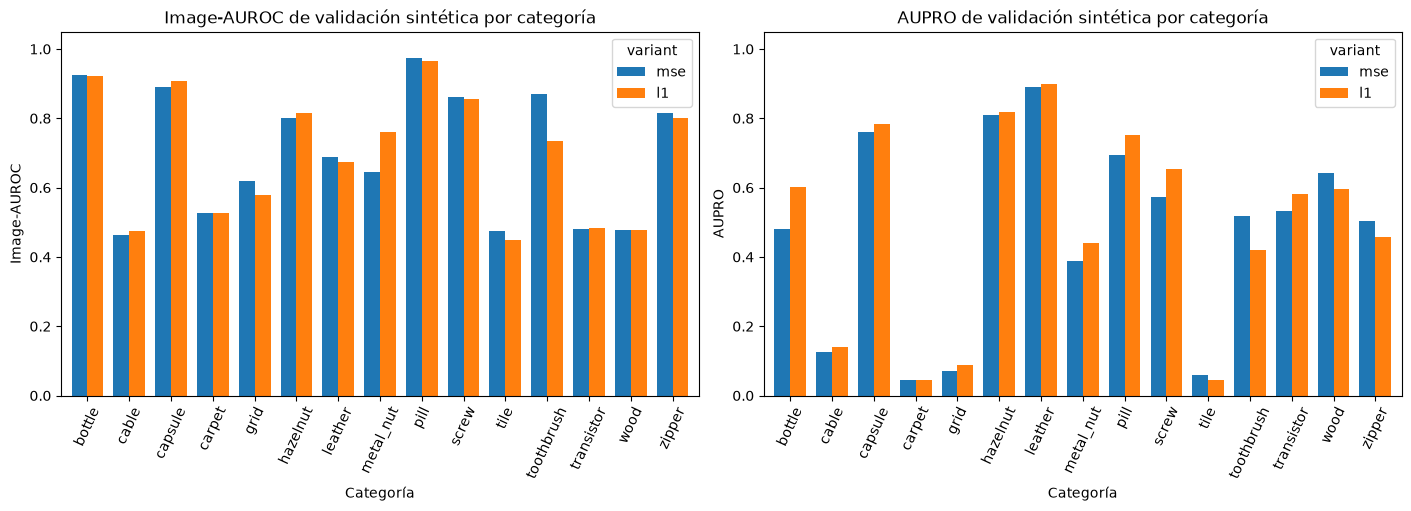

In [5]:
fig, axes = plt.subplots(1,2,figsize=(14,5),constrained_layout=True)
for ax, metric, label in zip(axes,['image_auroc','aupro'],['Image-AUROC','AUPRO']):
    pivot = model_df.pivot(index='category',columns='variant',values=metric)[['mse', 'l1']]
    pivot.sort_index().plot.bar(ax=ax,width=0.76)
    ax.set_title(f'{label} de validación sintética por categoría')
    ax.set_ylabel(label); ax.set_xlabel('Categoría'); ax.set_ylim(0,1.05)
    ax.tick_params(axis='x',rotation=65)
export_figure('autoencoder_validation_by_category.png')
p = model_df.pivot(index='category',columns='variant',values='image_auroc')
v1,v2 = ['mse', 'l1']
d = p[v2]-p[v1]

En Image-AUROC de validación, l1 supera a mse en 6 categorías, empata en 0 y pierde en 9. Diferencia media -0.0056

### Curvas de entrenamiento — Autoencoder
Las pérdidas se muestran separadamente por variante porque MSE y L1 no tienen la misma escala. Los puntos de Image-AUROC corresponden a validaciones de los checkpoints a lo largo del entrenamiento, no a resultados finales del test. Se grafican las 15 categorías (cada panel contiene las dos variantes)

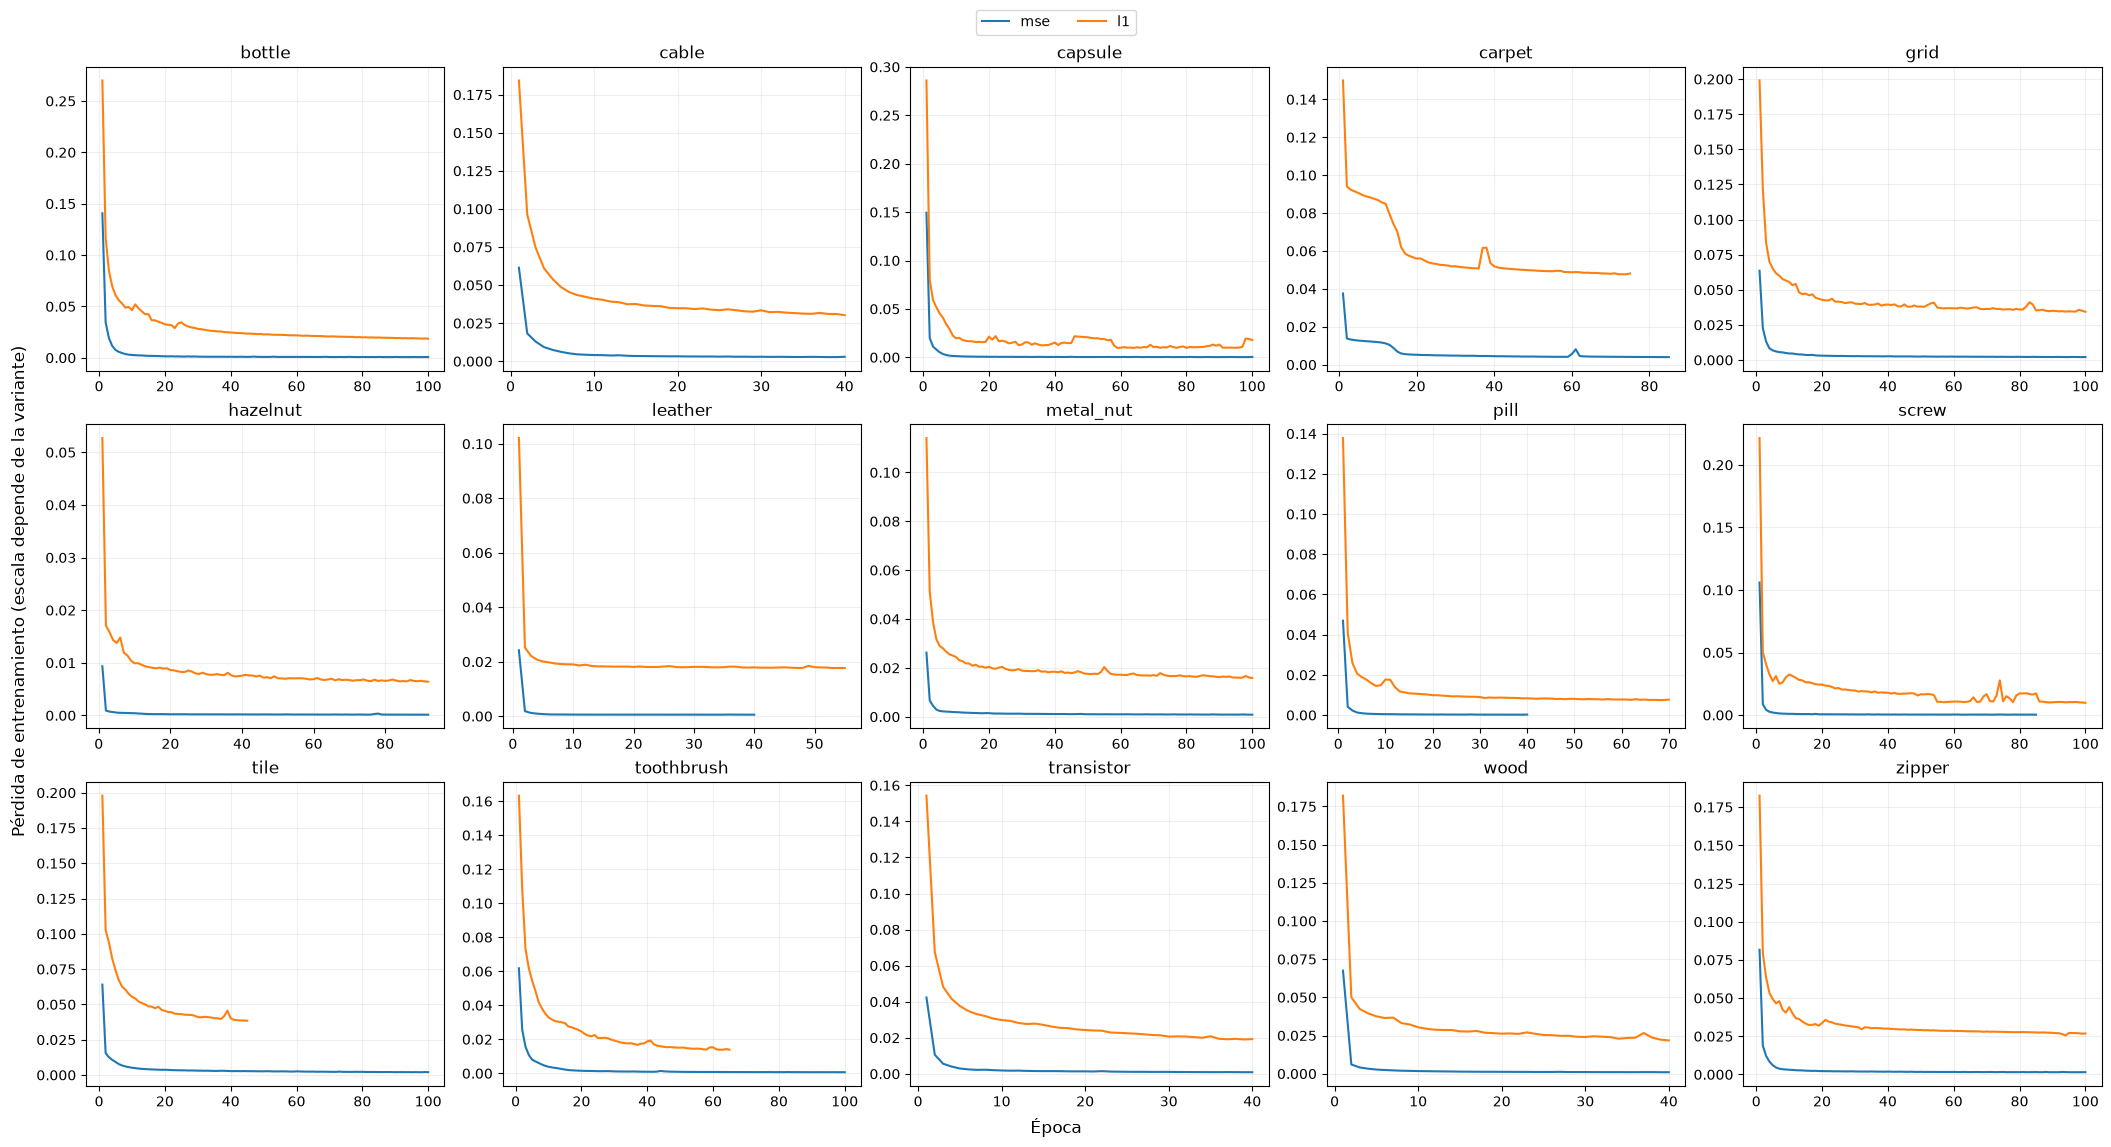

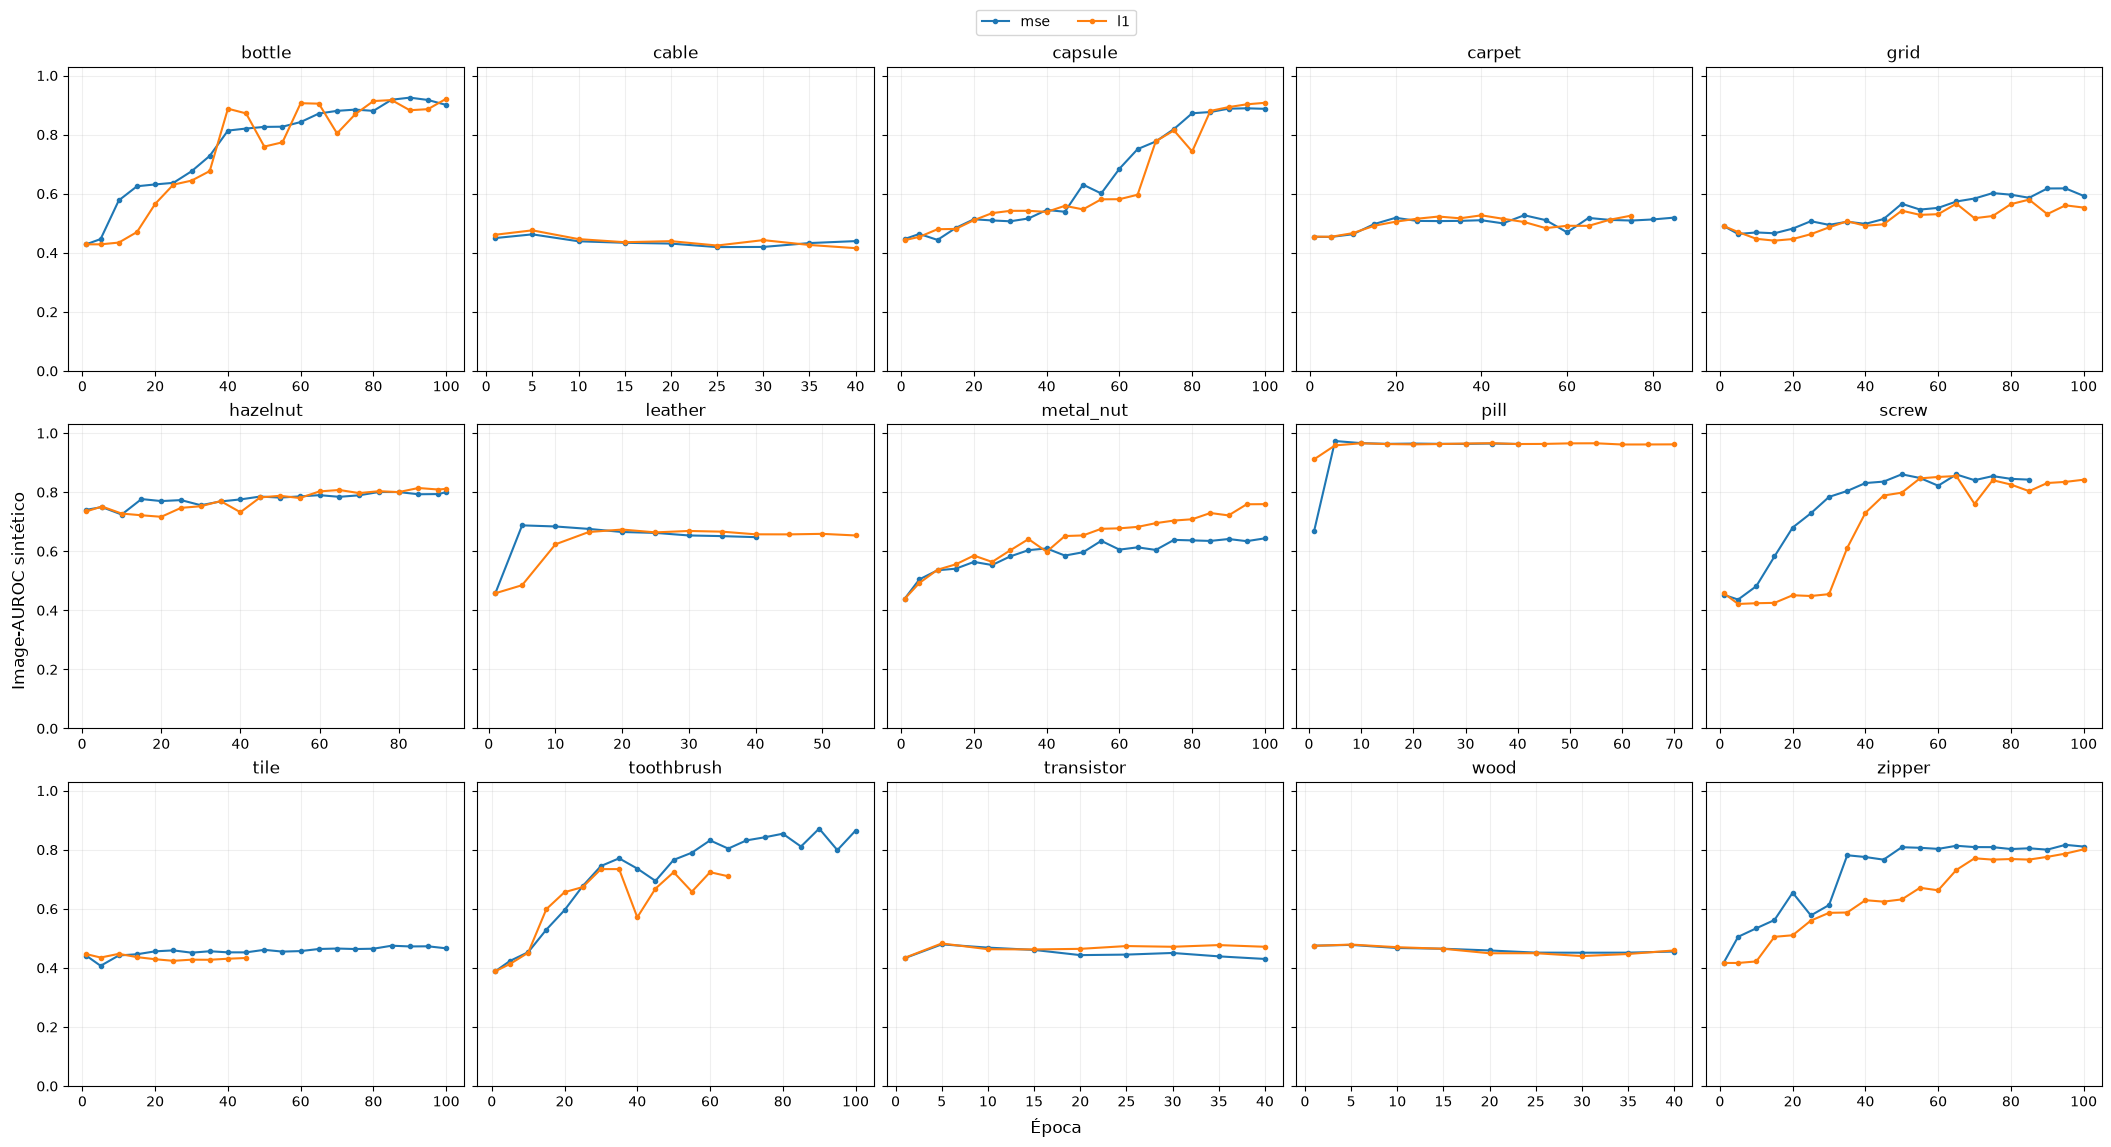

In [6]:
record_lookup = {(r['model'],r['category'],r['variant']):r for r in records}

def show_training_curves(model, metric, filename):
    categories = sorted(train_df.category.unique())
    fig,axes = plt.subplots(3,5,figsize=(21,11),sharex=False,sharey=(metric=='validation_image_auroc'),constrained_layout=True)
    for category,ax in zip(categories,axes.flat):
        for variant in VARIANT_ORDER[model]:
            history = record_lookup[(model,category,variant)].get('training_history',[])
            x=[h['epoch'] for h in history if metric in h]
            y=[h[metric] for h in history if metric in h]
            ax.plot(x,y,marker='.' if metric=='validation_image_auroc' else None,label=variant)
        ax.set_title(category)
        if metric=='validation_image_auroc': ax.set_ylim(0,1.03)
        ax.grid(alpha=.2)
    handles, labels = axes.flat[0].get_legend_handles_labels()
    fig.legend(handles,labels,loc='upper center',ncol=2,bbox_to_anchor=(.5,1.035))
    fig.supxlabel('Época');fig.supylabel('Image-AUROC sintético' if metric=='validation_image_auroc' else 'Pérdida de entrenamiento (escala depende de la variante)')
    export_figure(filename)

show_training_curves('autoencoder','training_loss','autoencoder_train_loss_15_categories.png')
show_training_curves('autoencoder','validation_image_auroc','autoencoder_validation_auroc_15_categories.png')
last = train_df.query("model=='autoencoder'").sort_values('image_auroc')

Las curvas de pérdida documentan la optimización, pero una pérdida decreciente no garantiza detectar defectos. MSE y L1 no son comparables por magnitud absoluta

Categorías con menor AUROC de validación del Autoencoder: tile, cable, wood. El criterio de selección fue el mayor AUROC observado

## Modelo 2 - PatchCore

Se implementó PatchCore utilizando ResNet18 preentrenada en ImageNet para extraer características de imágenes normales. Las anomalías se detectan mediante la distancia al vecino normal más cercano, sin reconstruir imágenes ni entrenar nuevos pesos

Arquitectura: Imagen → ResNet18 congelada (layer2 + layer3) → Características de parches → Coreset → Banco de memoria → Distancia NN → Mapa de anomalías

Se eligió porque aprovecha características visuales preentrenadas y permite detectar anomalías sin entrenar una red desde cero, proporcionando una alternativa al enfoque basado en reconstrucción

Hipótesis H2: El tamaño del banco de memoria influye en la precisión y eficiencia del modelo. Se compara conservar el 1 % frente al 5 % de las características, utilizando todas las imágenes normales de entrenamiento

Entrenamiento: No utiliza descenso de gradiente ni épocas. El ajuste consiste en extraer características y seleccionar el coreset. El tiempo de inferencia depende también del tamaño del banco y de la búsqueda de vecinos

Objetivo: Determinar qué proporción de características ofrece el mejor equilibrio entre capacidad de detección, memoria y tiempo de inferencia

In [7]:
model_df = train_df.query("model == 'patchcore'").copy()
assert len(model_df) == 30
summary = (model_df.groupby('variant')
    .agg(image_auroc_mean=('image_auroc','mean'), image_auroc_std=('image_auroc','std'),
         aupro_mean=('aupro','mean'), fit_seconds_mean=('fit_seconds','mean'),
         fit_seconds_median=('fit_seconds','median'),
         best_epoch_median=('best_epoch','median'))
    .round(3))
display(summary)
display(model_df[['category','variant','epochs_run','best_epoch','image_auroc','aupro','fit_seconds']].round(3))

,image_auroc_mean,image_auroc_std,aupro_mean,fit_seconds_mean,fit_seconds_median,best_epoch_median
variant,,,,,,
coreset_1,0.916,0.093,0.868,4.505,4.617,NaN
coreset_5,0.919,0.092,0.870,8.918,8.413,NaN


,category,variant,epochs_run,best_epoch,image_auroc,aupro,fit_seconds
60,bottle,coreset_1,NaN,NaN,0.999,0.904,3.189
61,bottle,coreset_5,NaN,NaN,0.999,0.905,7.582
62,cable,coreset_1,NaN,NaN,0.991,0.805,5.053
63,cable,coreset_5,NaN,NaN,0.993,0.825,8.131
64,capsule,coreset_1,NaN,NaN,0.998,0.922,4.617
65,capsule,coreset_5,NaN,NaN,0.998,0.922,7.299
66,carpet,coreset_1,NaN,NaN,0.750,0.804,6.249
67,carpet,coreset_5,NaN,NaN,0.757,0.805,10.295
68,grid,coreset_1,NaN,NaN,0.796,0.873,4.283
69,grid,coreset_5,NaN,NaN,0.808,0.879,7.848


Los resultados anteriores corresponden a 30 ajustes del PatchCore (dos variantes por cada una de las 15 categorías). La tabla contiene resultados de entrenamiento/ajuste y validación sintética

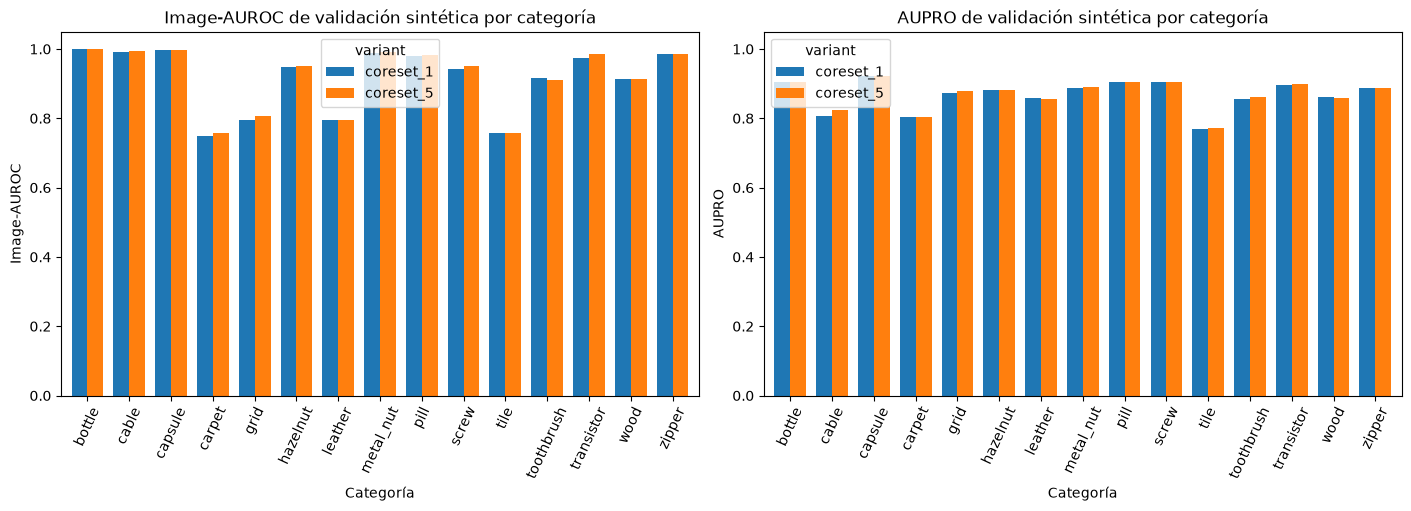

In [8]:
fig, axes = plt.subplots(1,2,figsize=(14,5),constrained_layout=True)

for ax, metric, label in zip(axes,['image_auroc','aupro'],['Image-AUROC','AUPRO']):
    pivot = model_df.pivot(index='category',columns='variant',values=metric)[['coreset_1', 'coreset_5']]
    pivot.sort_index().plot.bar(ax=ax,width=0.76)
    ax.set_title(f'{label} de validación sintética por categoría')
    ax.set_ylabel(label); ax.set_xlabel('Categoría'); ax.set_ylim(0,1.05)
    ax.tick_params(axis='x',rotation=65)

export_figure('patchcore_validation_by_category.png')
p = model_df.pivot(index='category',columns='variant',values='image_auroc')
v1,v2 = ['coreset_1', 'coreset_5']
d = p[v2]-p[v1]

En Image-AUROC de validación, coreset_5 supera a coreset_1 en 10 categorías, empata en 2 y pierde en 3. Diferencia media +0.0030

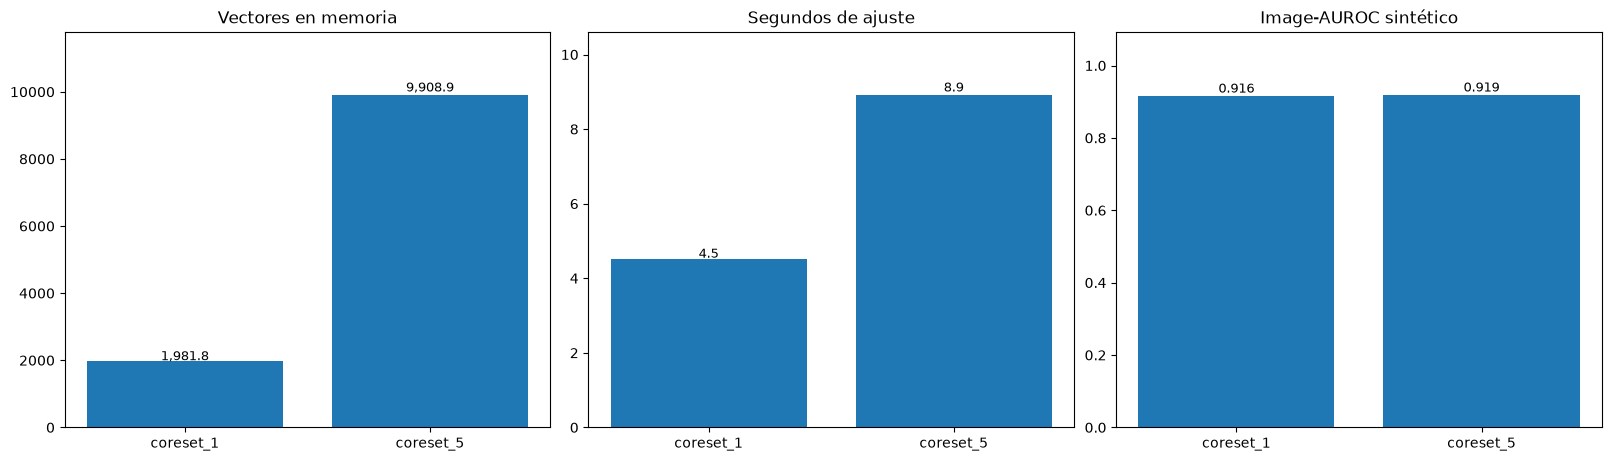

In [9]:
patch = train_df.query("model=='patchcore'")
fig,axes=plt.subplots(1,3,figsize=(16,4.5),constrained_layout=True)
for ax,metric,label in zip(axes,['retained_features','fit_seconds','image_auroc'],['Vectores en memoria','Segundos de ajuste','Image-AUROC sintético']):
    a=patch.groupby('variant')[metric].mean().reindex(['coreset_1','coreset_5'])
    ax.bar(a.index,a.values)
    ax.set_title(label)
    for i,val in enumerate(a.values): ax.text(i,val*1.01,f'{val:.3f}' if metric=='image_auroc' else f'{val:,.1f}',ha='center',fontsize=9)
    ax.set_ylim(0,max(a.values)*1.19)
export_figure('patchcore_memory_time_performance.png')
p=patch.pivot(index='category',columns='variant',values='image_auroc')
t=patch.pivot(index='category',columns='variant',values='fit_seconds')

Aumentar el coreset del 1 % al 5 % mejora el AUROC medio en 0.0030, pero incrementa el tiempo de ajuste en 4.41 segundos. Pero también es necesario evaluar también el consumo de memoria y la latencia de inferencia para determinar si el aumento del banco se justifica

## Modelo - Reconstrucción y segmentación con dos U-Net

Se implementó una arquitectura de dos U-Net que aprende a reconstruir imágenes normales y segmentar anomalías mediante defectos sintéticos generados durante el entrenamiento

Arquitectura: Imagen normal + perturbación sintética → U-Net 1 (reconstrucción 3→3) → Concatenación con imagen alterada (6 canales) → U-Net 2 (segmentación 6→1) → Mapa de anomalías

Se eligió porque combina reconstrucción y segmentación, permitiendo aprender tanto los patrones normales como la localización de defectos mediante supervisión sintética

Hipótesis H3: Una arquitectura de mayor capacidad mejora la detección de anomalías. Se comparan dos configuraciones: small [16,32,64] y large [16,32,64,128]

Entrenamiento: Se utiliza pérdida L1 para reconstrucción y BCE/Dice para segmentación, con un máximo de 100 épocas, paciencia de 8 comprobaciones y presupuesto nominal de 600 segundos por variante

Objetivo: Determinar si aumentar la profundidad de la arquitectura mejora la detección y segmentación de anomalías, considerando su costo computacional

Limitación: La validación utiliza perturbaciones similares a las del entrenamiento, por lo que sus resultados pueden sobreestimar el desempeño ante defectos reales

In [10]:
model_df = train_df.query("model == 'dual_unet'").copy()
assert len(model_df) == 30
summary = (model_df.groupby('variant')
    .agg(image_auroc_mean=('image_auroc','mean'), image_auroc_std=('image_auroc','std'),
         aupro_mean=('aupro','mean'), fit_seconds_mean=('fit_seconds','mean'),
         fit_seconds_median=('fit_seconds','median'),
         best_epoch_median=('best_epoch','median'))
    .round(3))
display(summary)
display(model_df[['category','variant','epochs_run','best_epoch','image_auroc','aupro','fit_seconds']].round(3))

,image_auroc_mean,image_auroc_std,aupro_mean,fit_seconds_mean,fit_seconds_median,best_epoch_median
variant,,,,,,
large,0.967,0.041,0.964,565.195,601.639,60.0
small,0.913,0.105,0.936,504.964,601.705,65.0


,category,variant,epochs_run,best_epoch,image_auroc,aupro,fit_seconds
30,bottle,large,100.0,60.0,0.991,0.970,583.569
31,bottle,small,100.0,70.0,0.989,0.965,498.256
32,cable,large,75.0,70.0,0.970,0.967,602.890
33,cable,small,87.0,87.0,0.994,0.955,602.570
34,capsule,large,80.0,60.0,1.000,0.984,601.574
35,capsule,small,96.0,96.0,0.995,0.956,602.991
36,carpet,large,58.0,58.0,0.986,0.969,601.639
37,carpet,small,68.0,30.0,0.755,0.893,609.480
38,grid,large,82.0,80.0,1.000,0.988,607.216
39,grid,small,96.0,70.0,1.000,0.968,606.337


Los resultados corresponden a 30 ejecuciones del modelo M3 (Dual U-Net): dos variantes para cada una de las 15 categorías. La tabla presenta métricas de entrenamiento y validación sintética

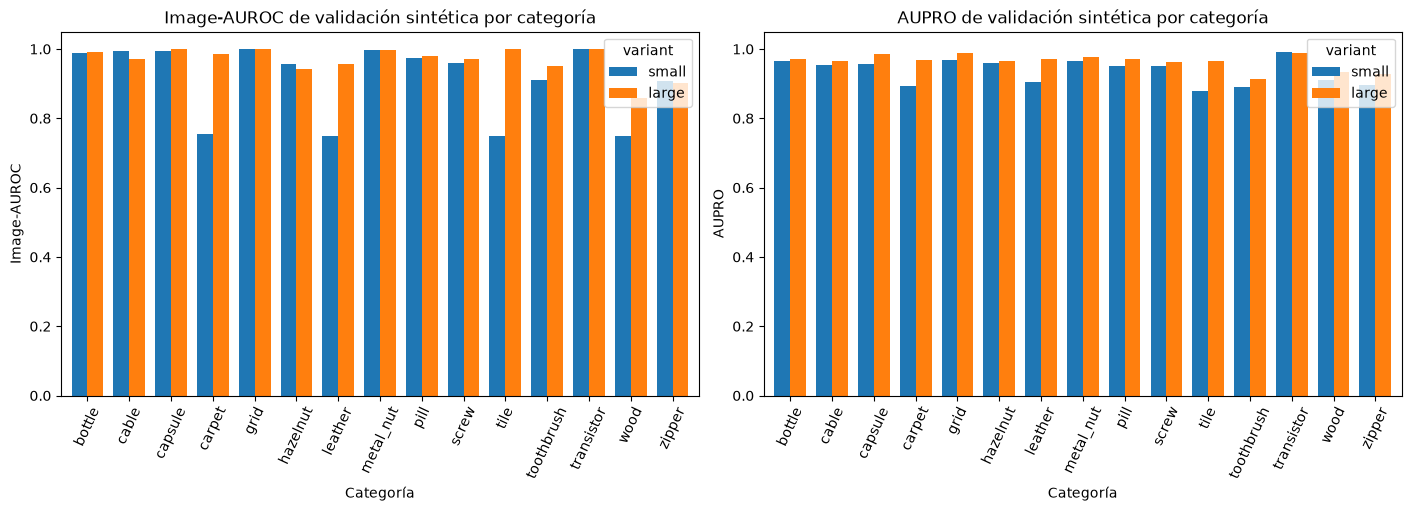

In [11]:
fig, axes = plt.subplots(1,2,figsize=(14,5),constrained_layout=True)
for ax, metric, label in zip(axes,['image_auroc','aupro'],['Image-AUROC','AUPRO']):
    pivot = model_df.pivot(index='category',columns='variant',values=metric)[['small', 'large']]
    pivot.sort_index().plot.bar(ax=ax,width=0.76)
    ax.set_title(f'{label} de validación sintética por categoría')
    ax.set_ylabel(label); ax.set_xlabel('Categoría'); ax.set_ylim(0,1.05)
    ax.tick_params(axis='x',rotation=65)

export_figure('dual_unet_validation_by_category.png')
p = model_df.pivot(index='category',columns='variant',values='image_auroc')
v1,v2 = ['small', 'large']
d = p[v2]-p[v1]

En la validación sintética, large supera a small en 9 categorías, empata en 1 y obtiene resultados inferiores en 5, con una mejora media de 0.0543 en Image-AUROC. Sin embargo, estos resultados no garantizan un mejor desempeño ante anomalías reales

## Curvas de entrenamiento

Ambas variantes utilizan la misma función objetivo, lo que permite comparar sus curvas de pérdida. Sin embargo, la pérdida refleja el ajuste durante el entrenamiento, mientras que el AUROC sintético evalúa la capacidad de distinguir imágenes normales de anómalas

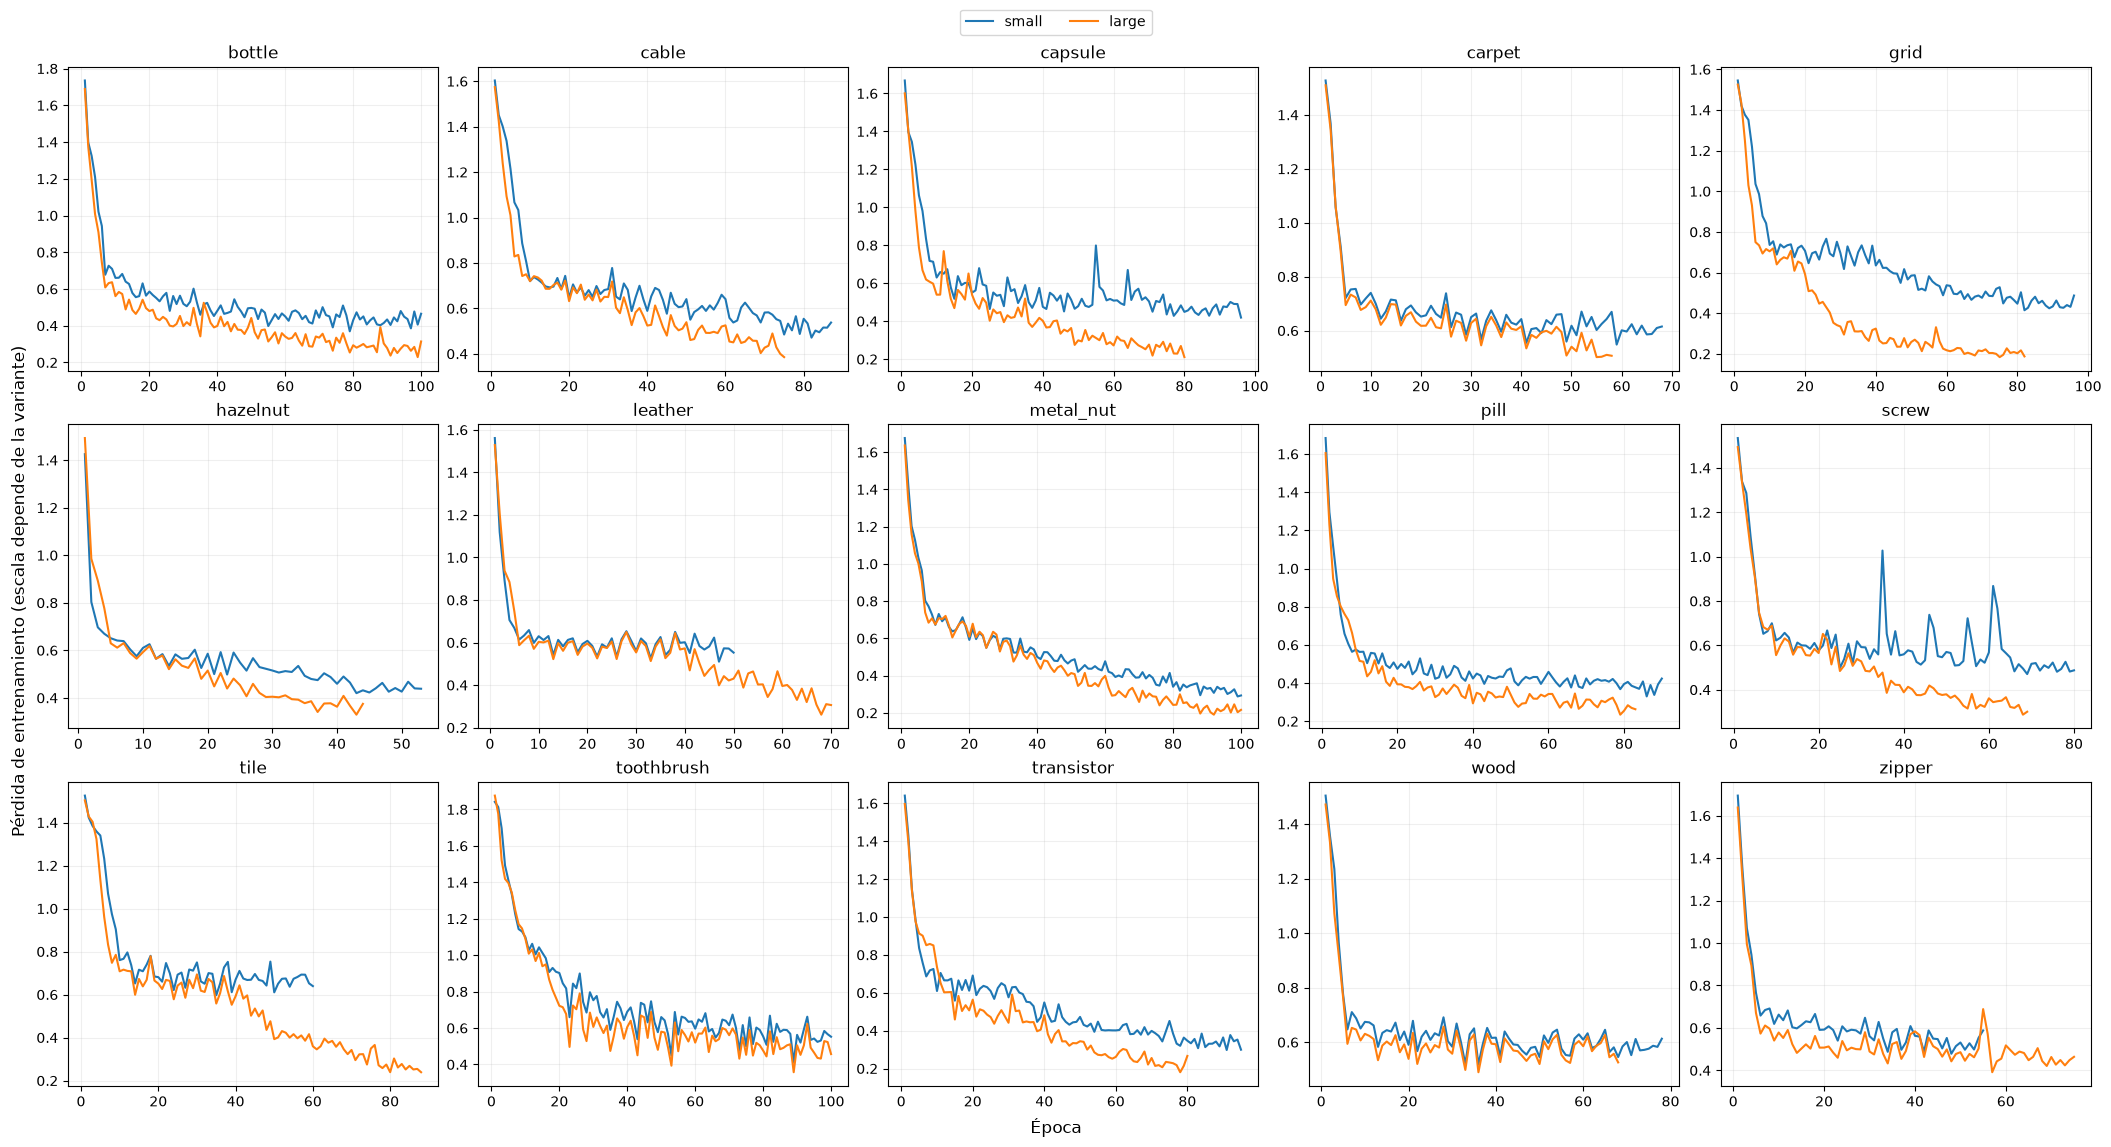

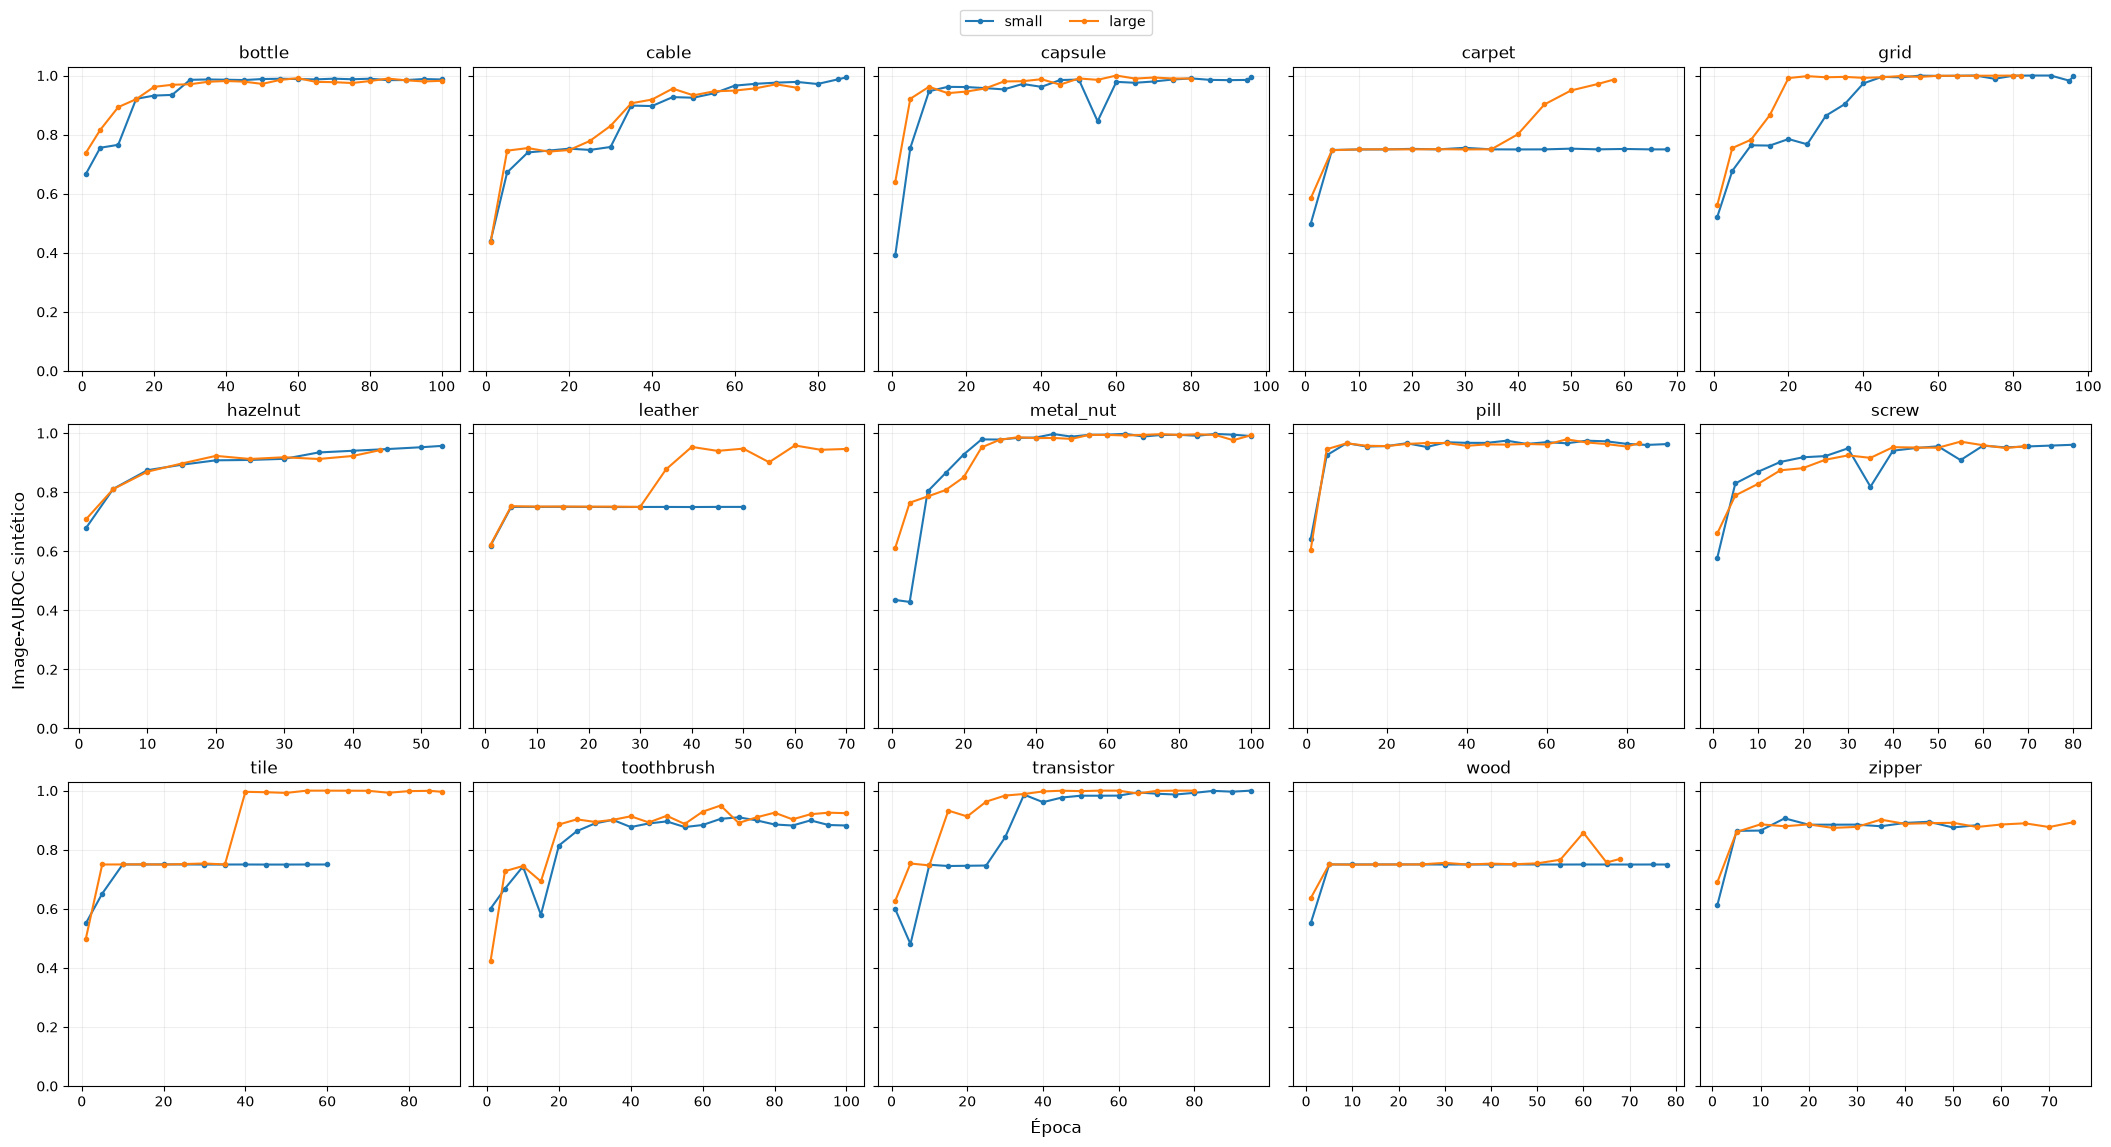

In [12]:
show_training_curves('dual_unet','training_loss','dual_unet_train_loss_15_categories.png')
show_training_curves('dual_unet','validation_image_auroc','dual_unet_validation_auroc_15_categories.png')
unu=train_df.query("model=='dual_unet'")

Curvas de entrenamiento: Las pérdidas reflejan el aprendizaje de reconstrucción y segmentación con anomalías sintéticas, pero no permiten confirmar la generalización a defectos reales

Validación: La variante large alcanza un AUROC medio de 0.9669, frente a 0.9126 de small. Los checkpoints se seleccionaron sin utilizar el conjunto de test real, cuyo desempeño se evaluará en el siguiente notebook

## Selección de variantes para la evaluación externa

Para cada combinación de modelo y categoría, se selecciona la variante con mayor Image-AUROC de validación sintética. Los empates se resuelven mediante el AUPRO, el menor tiempo de ajuste y, finalmente, el nombre de la variante

Los mejores checkpoints y los umbrales de clasificación y segmentación se determinan exclusivamente con la validación sintética, sin utilizar datos del test real

El segundo notebook evaluará los 45 detectores seleccionados, manteniendo fijos sus parámetros y umbrales para garantizar una evaluación independiente

In [13]:
def choose_variant(group):
    order={name:i for i,name in enumerate(VARIANT_ORDER[group.model.iloc[0]])}
    return group.sort_values(['image_auroc','aupro','fit_seconds','variant'],ascending=[False,False,True,True]).iloc[0]

selected=[]
for (category,model),g in train_df.groupby(['category','model']):
    selected.append(choose_variant(g))
    
selection=pd.DataFrame(selected).sort_values(['category','model'])
assert len(selection)==45
selection.to_csv(TABLE_DIR/'training_selected_45.csv',index=False)
display(selection[['category','model','variant','image_auroc','aupro','best_epoch','fit_seconds']].round(4))
display(pd.crosstab(selection.model,selection.variant))

,category,model,variant,image_auroc,aupro,best_epoch,fit_seconds
1,bottle,autoencoder,mse,0.9252,0.4816,90.0,231.897
30,bottle,dual_unet,large,0.9912,0.9702,60.0,583.569
61,bottle,patchcore,coreset_5,0.9994,0.9046,NaN,7.582
2,cable,autoencoder,l1,0.4759,0.1406,5.0,152.464
33,cable,dual_unet,small,0.9940,0.9547,87.0,602.570
63,cable,patchcore,coreset_5,0.9930,0.8246,NaN,8.131
4,capsule,autoencoder,l1,0.9077,0.7836,100.0,356.103
34,capsule,dual_unet,large,1.0000,0.9844,60.0,601.574
64,capsule,patchcore,coreset_1,0.9985,0.9219,NaN,4.617
7,carpet,autoencoder,mse,0.5270,0.0439,50.0,435.588


variant,coreset_1,coreset_5,l1,large,mse,small
model,,,,,,
autoencoder,0,0,6,0,9,0
dual_unet,0,0,0,9,0,6
patchcore,3,12,0,0,0,0


La validación sintética permitió seleccionar 45 checkpoints, uno por modelo y categoría. El conjunto de test real se utilizará exclusivamente para la evaluación final en el siguiente notebook

## Conclusiones de las hipótesis H1–H3

* H1 — Autoencoder (MSE vs. L1): MSE obtuvo un Image-AUROC medio ligeramente superior (0,7005 vs. 0,6949) y ganó en 9 de 15 categorías. Sin embargo, L1 alcanzó mejor AUPRO (0,4881 vs. 0,4723). No se observa una ventaja concluyente de MSE

* H2 — PatchCore (1 % vs. 5 %): El coreset del 5 % mejoró marginalmente el Image-AUROC (0,9190 vs. 0,9160) y el AUPRO (0,8703 vs. 0,8675), pero casi duplicó el tiempo de ajuste (8,92 vs. 4,50 s). El beneficio adicional es reducido frente al costo computacional

* H3 — Doble U-Net (Small vs. Large): Large superó a Small en Image-AUROC (0,9669 vs. 0,9126) y AUPRO (0,9636 vs. 0,9355), con mayor tiempo de ajuste (565 vs. 505 s). La arquitectura más profunda mostró mejores resultados en validación sintética, a costa de mayor cómputo.